# Experiment 08 — BCE vs CE Loss

In this experiment, we compare two loss functions for the same
8-class vehicle classification problem:

- CrossEntropyLoss (CE)
- BCEWithLogitsLoss (BCE)

The goal is to understand how the choice of loss function affects:

- training and validation loss
- validation accuracy
- per-class precision, recall, and F1-score
- confidence behavior
- prediction errors

This is a controlled experiment, so all training conditions remain
the same except for the loss function and the corresponding target
representation.

## CE vs BCE for Multi-Class Classification

Our problem has 8 mutually exclusive classes. Each image belongs
to exactly one vehicle class.

### CrossEntropyLoss

For CE, the target is a single integer representing the correct class.

For example:

    label = 3

The model produces 8 logits:

    [z0, z1, z2, z3, z4, z5, z6, z7]

CrossEntropyLoss internally applies the appropriate normalization
and compares the prediction with the correct class.

The predicted class is:

    argmax(logits)

### BCEWithLogitsLoss

For BCE, we represent the class using a one-hot vector.

For example, if the correct class is 3:

    [0, 0, 0, 1, 0, 0, 0, 0]

BCE treats each output as an independent binary classification
problem.

Therefore, BCE does not explicitly enforce that the 8 outputs
form a mutually exclusive probability distribution.

For evaluation, we still select the class with the largest logit:

    argmax(logits)

This allows us to compare BCE and CE using the same multiclass
classification metrics.

In [1]:
import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from collections import Counter

from torch.optim import Adam
from torchvision import transforms

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)

from models import SimpleCNN

from train import train_model,train_model_bce

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)

### Configuration

In [2]:
SEED = 42
set_seed(SEED)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_CLASSES = 8

config_bce = {
    "loss": "BCEWithLogitsLoss",
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": 0,
    "dropout": 0.0,
    "use_gap": False,
    "epochs": EPOCHS,
    "seed": SEED
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


### Paths

In [3]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"


print("Training directory:", MERGED_TRAIN_DIR)


print("Training directory exists:", MERGED_TRAIN_DIR.exists())

Training directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train
Training directory exists: True


### Transforms as the Baseline Model

In [4]:
baseline_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Create Train/Validation Datasets

In [5]:
train_dataset, val_dataset, train_indices, val_indices,class_to_idx= \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=baseline_transform,
        val_transform=baseline_transform,
        test_size=0.2,
        seed=SEED
    )

### Class Names

In [6]:
full_dataset = datasets.ImageFolder(
    MERGED_TRAIN_DIR
)

class_names = full_dataset.classes
class_to_idx = full_dataset.class_to_idx

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

print("\nNumber of classes:", len(class_names))

Classes:
0 -> ambulance
1 -> autobus
2 -> kamyun
3 -> kamyunet
4 -> minibus
5 -> savari
6 -> taxi
7 -> vanet

Number of classes: 8


### Data Loaders

In [7]:
train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 85
Number of validation batches: 22


### The Same Model as the Baseline Model

In [8]:
model_bce= SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
).to(DEVICE)

### BCE Loss

In [9]:
criterion_bce = nn.BCEWithLogitsLoss()

optimizer_bce = torch.optim.Adam(
    model_bce.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0
)

### Train Model BCE

In [10]:
history_bce, best_val_acc_bce = train_model_bce(
    model=model_bce,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_bce,
    optimizer=optimizer_bce,
    device=DEVICE,
    epochs=EPOCHS,
    model_name="bce_loss",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_bce,
    num_classes=NUM_CLASSES,
    
)

Epoch [1/10] Train Loss: 0.3988 --- Train Acc: 0.4220 --- Val Loss: 0.2331 --- Val Acc: 0.5994 --- LR: 0.001000
Epoch [2/10] Train Loss: 0.1935 --- Train Acc: 0.6959 --- Val Loss: 0.1799 --- Val Acc: 0.7290 --- LR: 0.001000
Epoch [3/10] Train Loss: 0.1265 --- Train Acc: 0.8209 --- Val Loss: 0.1650 --- Val Acc: 0.7555 --- LR: 0.001000
Epoch [4/10] Train Loss: 0.0767 --- Train Acc: 0.9060 --- Val Loss: 0.1640 --- Val Acc: 0.7658 --- LR: 0.001000
Epoch [5/10] Train Loss: 0.0367 --- Train Acc: 0.9698 --- Val Loss: 0.1776 --- Val Acc: 0.7850 --- LR: 0.001000
Epoch [6/10] Train Loss: 0.0201 --- Train Acc: 0.9867 --- Val Loss: 0.2013 --- Val Acc: 0.7761 --- LR: 0.001000
Epoch [7/10] Train Loss: 0.0078 --- Train Acc: 0.9985 --- Val Loss: 0.2457 --- Val Acc: 0.7703 --- LR: 0.001000
Epoch [8/10] Train Loss: 0.0034 --- Train Acc: 0.9996 --- Val Loss: 0.2707 --- Val Acc: 0.7820 --- LR: 0.001000
Epoch [9/10] Train Loss: 0.0015 --- Train Acc: 1.0000 --- Val Loss: 0.2731 --- Val Acc: 0.7791 --- LR: 0

### Training Curves

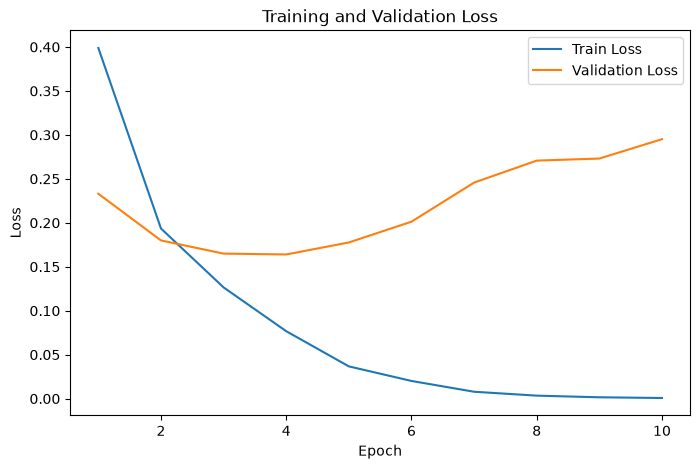

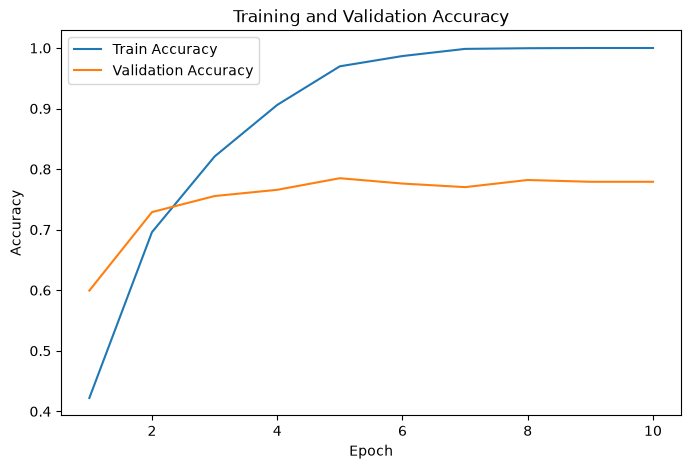

In [11]:
plot_training_history(history_bce)

### Best Epoch BCE

In [12]:
best_epoch_bce = np.argmax(
    history_bce["val_accuracy"]
) + 1

print("Best epoch:", best_epoch_bce)
print("Best validation accuracy:", best_val_acc_bce)

Best epoch: 5
Best validation accuracy: 0.7849779086892489


### Load Best CheckPoint for CE and BCE Model

In [13]:
# ================
# CE Loss
# ================
print ("CE Loss")
checkpoint_ce = torch.load(
    PROJECT_DIR
    / "checkpoints"
    / "baseline_cnn_best.pt",
    map_location=DEVICE
)

model_ce = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
).to(DEVICE)

model_ce.load_state_dict(
    checkpoint_ce["model_state_dict"]
)

print("Best epoch:", checkpoint_ce["epoch"])
print(
    "Best validation accuracy:",
    checkpoint_ce["val_accuracy"]
)
print(
    "Best Epoch Loss :",
    checkpoint_ce["val_loss"]
)
print ("="*30)


# ================
# BCE Loss
# ================
print ("BCE Loss")
bce_checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "bce_loss_best.pt"
)


bce_checkpoint = torch.load(
    bce_checkpoint_path,
    map_location=DEVICE
)

model_bce.load_state_dict(
    bce_checkpoint["model_state_dict"]
)

print("Best epoch:", bce_checkpoint["epoch"])
print(
    "Best validation accuracy:",
    bce_checkpoint["val_accuracy"]
)
print(
    "Best Epoch Loss :",
    bce_checkpoint["val_loss"]
)
print ("="*30)

CE Loss
Best epoch: 9
Best validation accuracy: 0.7893961708394698
Best Epoch Loss : 1.1164248662072183
BCE Loss
Best epoch: 5
Best validation accuracy: 0.7849779086892489
Best Epoch Loss : 0.1776302380265122


### Validation Prediction

In [14]:
true_labels_ce, predictions_ce = get_predictions(
    model=model_ce,
    loader=val_loader,
    device=DEVICE
)
print ("CE Loss Model")
print("Number of  validation predictions:", len(predictions_ce))
correct = (true_labels_ce == predictions_ce).sum()
print("Number of correct validation predictions:", correct)
accuracy = correct / len(predictions_ce)
print("Validation accuracy:", accuracy)

print("="*30)

true_labels_bce, predictions_bce = get_predictions(
    model=model_bce,
    loader=val_loader,
    device=DEVICE
)
print ("BCE Loss Model")
print("Number of  validation predictions:", len(predictions_bce))
correct = (true_labels_bce == predictions_bce).sum()
print("Number of correct validation predictions:", correct)
accuracy = correct / len(predictions_bce)
print("Validation accuracy:", accuracy)


CE Loss Model
Number of  validation predictions: 679
Number of correct validation predictions: 536
Validation accuracy: 0.7893961708394698
BCE Loss Model
Number of  validation predictions: 679
Number of correct validation predictions: 533
Validation accuracy: 0.7849779086892489


### Classification Report

In [15]:
print ("CE Model")
report = get_classification_report(
    model=model_ce,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

print ("="*30)

print ("BCE Model")
report = get_classification_report(
    model=model_bce,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

CE Model
              precision    recall  f1-score   support

   ambulance     0.8429    0.8082    0.8252        73
     autobus     0.8969    0.9255    0.9110        94
      kamyun     0.6699    0.6970    0.6832        99
    kamyunet     0.6316    0.6593    0.6452        91
     minibus     0.8553    0.7927    0.8228        82
      savari     0.8137    0.8300    0.8218       100
        taxi     0.9184    0.9091    0.9137        99
       vanet     0.6053    0.5610    0.5823        41

    accuracy                         0.7894       679
   macro avg     0.7792    0.7729    0.7756       679
weighted avg     0.7907    0.7894    0.7897       679

BCE Model
              precision    recall  f1-score   support

   ambulance     0.8833    0.7260    0.7970        73
     autobus     0.8544    0.9362    0.8934        94
      kamyun     0.6421    0.6162    0.6289        99
    kamyunet     0.6526    0.6813    0.6667        91
     minibus     0.8228    0.7927    0.8075        82
     

## CM and Normalized CM

CE Model


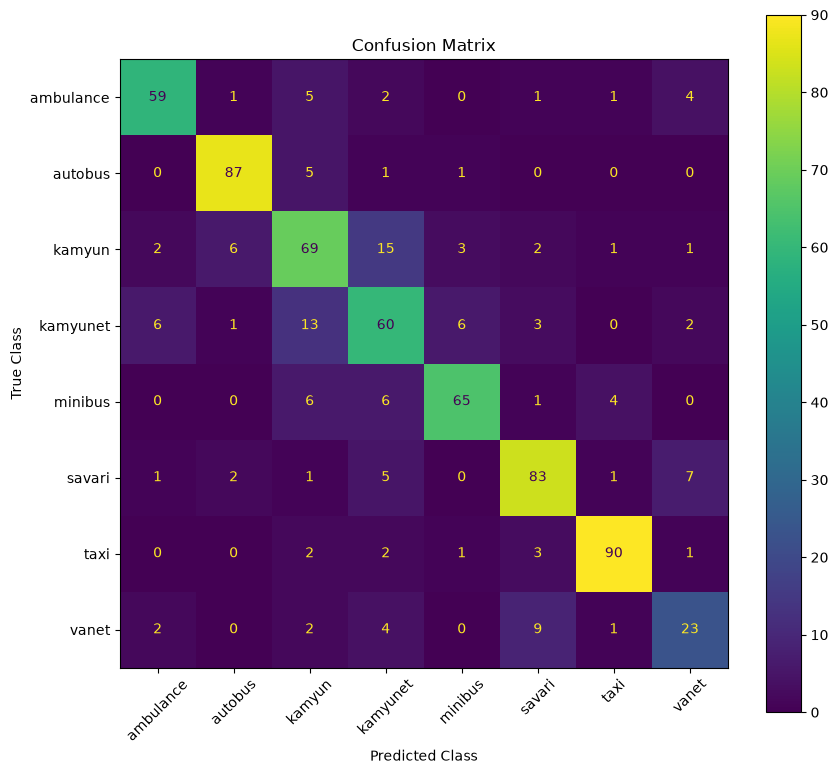

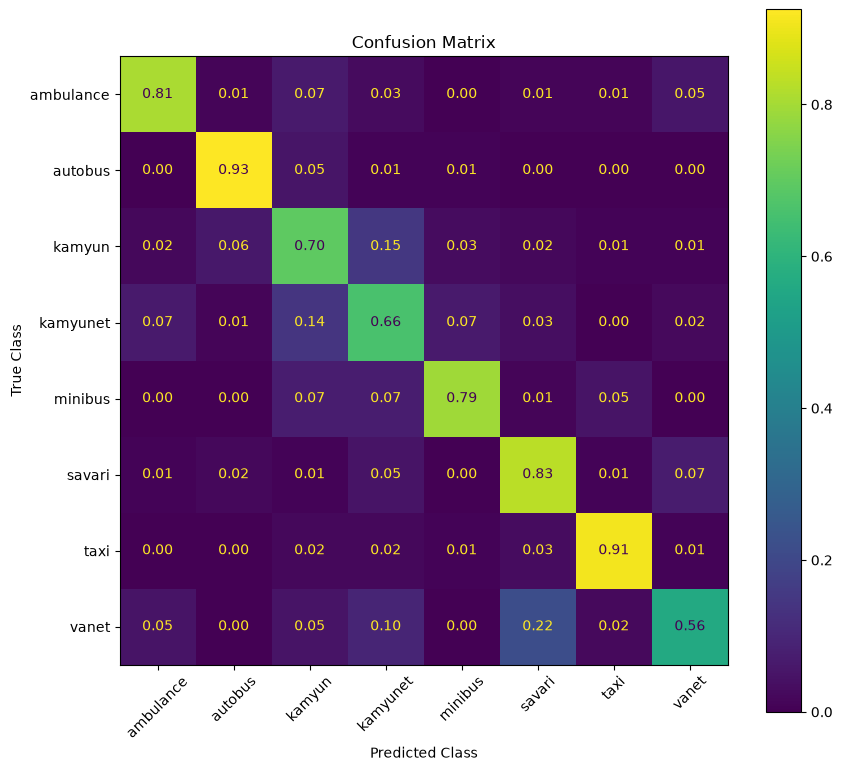

BCE Model


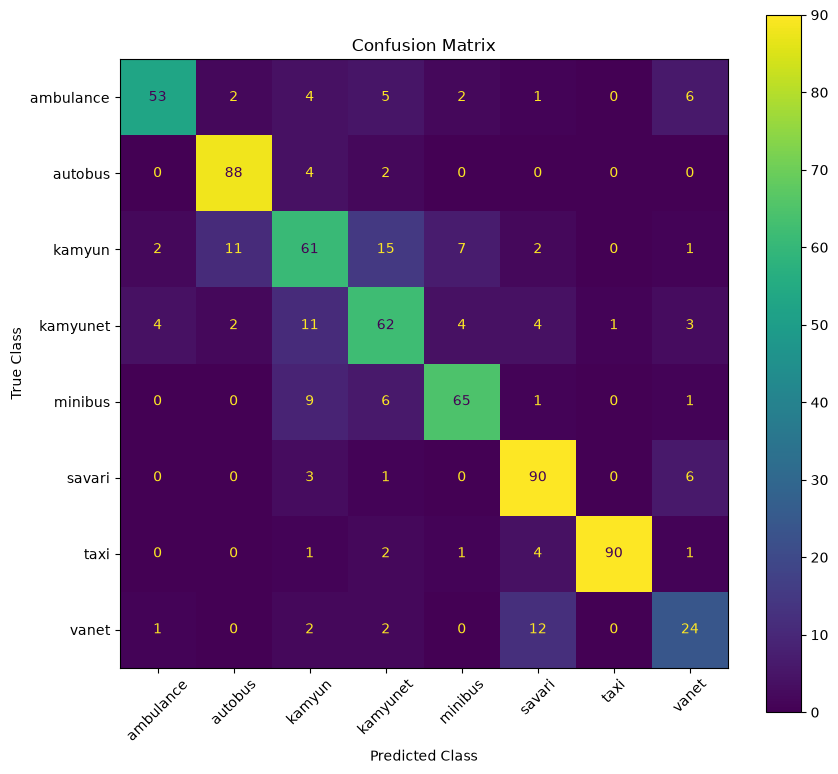

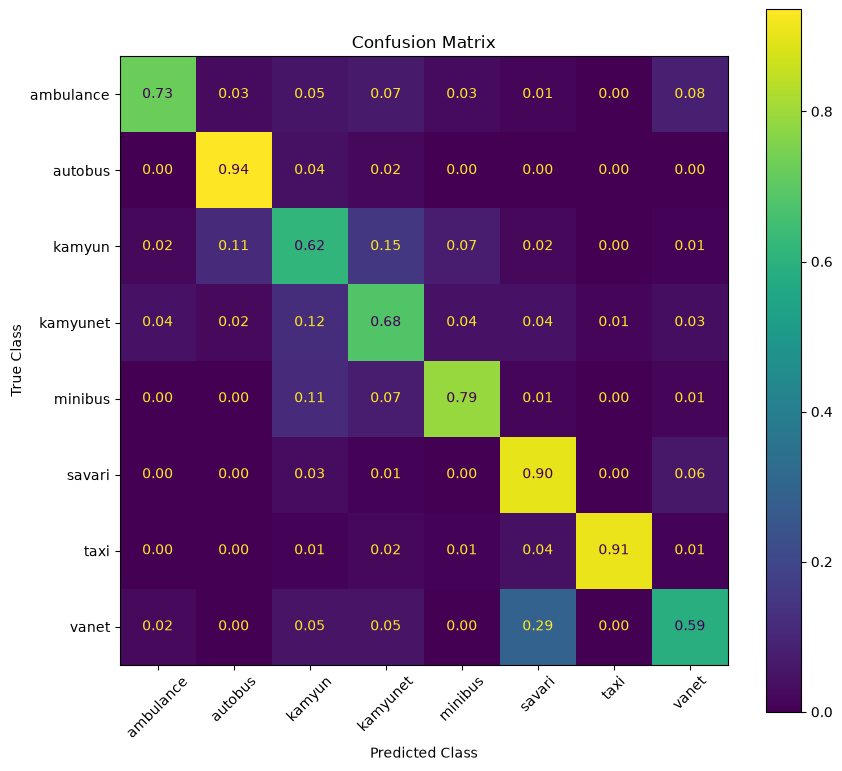

In [16]:
print ("CE Model")
cm = plot_confusion_matrix(
    model=model_ce,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

cm_normalized = plot_confusion_matrix(
    model=model_ce,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

print ("="*30)

print ("BCE Model")
cm = plot_confusion_matrix(
    model=model_bce,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

cm_normalized = plot_confusion_matrix(
    model=model_bce,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

### BCE Train/Validation Gap

In [17]:
best_epoch = np.argmax(
    history_bce["val_accuracy"]
)

best_train_accuracy = history_bce["train_accuracy"][best_epoch]
best_val_accuracy = history_bce["val_accuracy"][best_epoch]

print("Best Epoch BCE:", best_epoch + 1)

print(
    "Best Train Accuracy:",
    best_train_accuracy
)

print(
    "Best Validation Accuracy:",
    best_val_accuracy
)

print(
    "Train-Validation Gap:",
    best_train_accuracy - best_val_accuracy
)

Best Epoch BCE: 5
Best Train Accuracy: 0.9697751566531515
Best Validation Accuracy: 0.7849779086892489
Train-Validation Gap: 0.18479724796390262


### Final Comparision CE and BCE Loss

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
print ("CE Loss")
ce_accuracy = accuracy_score(
    true_labels_ce,
    predictions_ce
)

ce_precision = precision_score(
    true_labels_ce,
    predictions_ce,
    average="macro",
    zero_division=0
)

ce_recall = recall_score(
    true_labels_ce,
    predictions_ce,
    average="macro",
    zero_division=0
)

ce_f1 = f1_score(
    true_labels_ce,
    predictions_ce,
    average="macro",
    zero_division=0
)

print("CE Validation Results")
print("---------------------------")
print("Accuracy:", ce_accuracy)
print("Macro Precision:", ce_precision)
print("Macro Recall:", ce_recall)
print("Macro F1:", ce_f1)

print ("="*30)

print ("BCE Loss")
bce_accuracy = accuracy_score(
    true_labels_bce,
    predictions_bce
)

bce_precision = precision_score(
    true_labels_bce,
    predictions_bce,
    average="macro",
    zero_division=0
)

bce_recall = recall_score(
    true_labels_bce,
    predictions_bce,
    average="macro",
    zero_division=0
)

bce_f1 = f1_score(
    true_labels_bce,
    predictions_bce,
    average="macro",
    zero_division=0
)

print("BCE Validation Results")
print("---------------------------")
print("Accuracy:", bce_accuracy)
print("Macro Precision:", bce_precision)
print("Macro Recall:", bce_recall)
print("Macro F1:", bce_f1)

CE Loss
CE Validation Results
---------------------------
Accuracy: 0.7893961708394698
Macro Precision: 0.7792331715332621
Macro Recall: 0.772851361870305
Macro F1: 0.7756312812300503
BCE Loss
BCE Validation Results
---------------------------
Accuracy: 0.7849779086892489
Macro Precision: 0.7756421452817626
Macro Recall: 0.7683521996356554
Macro F1: 0.7700228410025494


## Confidence Behavior

CE and BCE produce different types of scores.

### CE

For CE, the model's logits are converted into a probability
distribution using softmax:

    probabilities = softmax(logits)

The probabilities sum to 1 across the eight classes.

### BCE

For BCE, sigmoid can be applied independently to each output:

    probabilities = sigmoid(logits)

These scores are independent binary scores and are not required
to sum to 1.

For multiclass prediction, we still select the class with the
largest logit.

Therefore, BCE confidence values should not be interpreted in
exactly the same way as CE softmax probabilities.

In [19]:
def get_ce_probabilities(model, loader, device):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)

            probs = torch.softmax(logits, dim=1)

            all_probs.append(probs.cpu())
            all_labels.append(labels)

    return (
        torch.cat(all_probs),
        torch.cat(all_labels)
    )



def get_bce_probabilities(model, loader, device):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)

            probs = torch.sigmoid(logits)

            all_probs.append(probs.cpu())
            all_labels.append(labels)

    return (
        torch.cat(all_probs),
        torch.cat(all_labels)
    )

In [20]:
ce_probs, ce_labels = get_ce_probabilities(
    model_ce,
    val_loader,
    DEVICE
)

bce_probs, bce_labels = get_bce_probabilities(
    model_bce,
    val_loader,
    DEVICE
)

ce_confidence, ce_predictions = ce_probs.max(dim=1)

bce_confidence, bce_predictions = bce_probs.max(dim=1)

### Important interpretation of BCE confidence

The maximum sigmoid score can be used as a simple confidence-like
score for comparison, but it is not equivalent to a calibrated
multiclass probability.

For CE, softmax explicitly normalizes the scores across classes.

For BCE, each sigmoid output is calculated independently.

Therefore:

- CE probabilities sum to 1.
- BCE sigmoid scores do not necessarily sum to 1.
- BCE can assign relatively high scores to multiple classes.
- Comparing raw CE softmax confidence and BCE sigmoid scores
  requires caution.

In [21]:
print("CE probabilities:")
print(ce_probs[:5])

print("\nBCE probabilities:")
print(bce_probs[:5])

CE probabilities:
tensor([[2.3934e-12, 9.9999e-01, 6.2443e-06, 9.8164e-09, 1.3107e-09, 6.6575e-14,
         1.3577e-10, 1.0910e-09],
        [1.3375e-02, 3.8181e-12, 3.0248e-16, 3.7871e-11, 7.0306e-14, 9.2727e-01,
         2.0918e-10, 5.9356e-02],
        [7.6346e-01, 2.0778e-06, 7.9368e-06, 9.6731e-03, 1.2922e-09, 9.4256e-02,
         1.4126e-06, 1.3260e-01],
        [5.2552e-09, 3.9190e-06, 3.9280e-10, 9.9910e-09, 6.2116e-09, 9.9983e-01,
         1.0672e-08, 1.6235e-04],
        [1.2644e-13, 1.7529e-10, 1.0000e+00, 1.5759e-07, 4.0344e-09, 1.5814e-18,
         2.5273e-07, 8.6353e-21]])

BCE probabilities:
tensor([[3.8889e-05, 9.9892e-01, 4.8934e-03, 1.0599e-03, 3.1077e-04, 1.5220e-04,
         2.0274e-04, 1.6764e-03],
        [5.2474e-03, 1.2880e-06, 3.3431e-06, 9.4095e-07, 7.3588e-08, 5.3010e-01,
         1.1369e-04, 2.0334e-01],
        [3.8744e-01, 5.3197e-04, 3.4824e-03, 4.8168e-03, 9.8637e-06, 1.7351e-02,
         5.4196e-05, 4.1898e-01],
        [1.2501e-04, 1.1243e-03, 7.9754e-

In [22]:
idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

for i in range(10):
    print(
        f"Image {i}: "
        f"True = {idx_to_class[ce_labels[i].item()]}, "
        f"Predicted = {idx_to_class[ce_predictions[i].item()]}, "
        f"Confidence = {ce_confidence[i].item():.4f}"
    )

Image 0: True = autobus, Predicted = autobus, Confidence = 1.0000
Image 1: True = savari, Predicted = savari, Confidence = 0.9273
Image 2: True = kamyunet, Predicted = ambulance, Confidence = 0.7635
Image 3: True = savari, Predicted = savari, Confidence = 0.9998
Image 4: True = kamyun, Predicted = kamyun, Confidence = 1.0000
Image 5: True = kamyun, Predicted = kamyunet, Confidence = 0.9885
Image 6: True = savari, Predicted = savari, Confidence = 0.9996
Image 7: True = kamyunet, Predicted = kamyunet, Confidence = 0.9639
Image 8: True = ambulance, Predicted = vanet, Confidence = 0.9888
Image 9: True = ambulance, Predicted = ambulance, Confidence = 0.9605
